# A10 erosion risk and infiltration per LGA

Erosion risk multiplies cropland slope (SRTM), rain intensity (IMERG 95th percentile wet-day rain) and soil erodibility (Williams K, relative to the Kaduna mean), scaled 0 to 1 across LGAs: it ranks LGAs against each other, it is not a soil loss in tonnes. Infiltration comes from saturated conductivity and the hydrologic soil group (A8, NEH 630 Ch. 7). Formulas: `model/land_risk.py`.

## Imports

In [1]:
# Third-party libraries only. Project code is imported two cells down, after the path
# setup, so this cell runs in any fresh kernel.
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

In [2]:
# Path setup: makes the notebook work whether Jupyter starts in notebooks/ or the repo
# root, and lets `import model` find the project package.
# Run from notebooks/ or the repo root: config paths are relative to the repo root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [3]:
# Project code: the tested functions in model/. The notebook calls them; it never
# redefines them, so its results match `python -m model.build` exactly.
from model import land_risk as lr
from model.io import write_csv
from model.settings import load_model_config

## 1. Inputs per LGA

In [4]:
# Load the static table and keep the erosion and infiltration inputs for every LGA.
# Scope: all 23 Kaduna LGAs.
cfg = load_model_config()
lrc = cfg.land_risk
static = pd.read_parquet(cfg.paths.static_features).set_index("lga")
inputs = static[
    [
        lrc.slope_column,
        lrc.intensity_column,
        lrc.erodibility_column,
        lrc.ksat_column,
        lrc.group_column,
        "imerg_suspect",
        "low_cropland",
    ]
]
inputs.describe().round(2)

,srtm_slope_pct_crop,imerg_p95_wet_mm,soil_erodibility_rel,soil_ksat_min_mm_h
count,23.00,23.00,23.00,23.00
mean,4.54,27.99,1.00,22.88
std,0.58,2.42,0.03,3.48
min,3.53,23.19,0.95,16.47
25%,4.12,26.40,0.97,20.95
50%,4.37,27.88,1.00,22.36
75%,5.06,29.34,1.03,25.68
max,5.55,31.80,1.05,28.04


## 2. Erosion index and what drives it

In [5]:
# Erosion index = slope x rain intensity x erodibility, scaled 0 to 1 across LGAs and
# banded into thirds, plus each term's share of the index (log departures).
slope, rain, k = (
    static[c] for c in (lrc.slope_column, lrc.intensity_column, lrc.erodibility_column)
)
raw = slope * rain * k
index = lr.erosion_index(slope, rain, k)
table = inputs.assign(
    erosion_raw=raw, erosion_index=index, erosion_band=lr.band(index, lrc.band_edges)
).join(lr.term_shares(slope, rain, k).add_prefix("driver_share_"))
{"highest / lowest raw erosion product": round(raw.max() / raw.min(), 2)}

{'highest / lowest raw erosion product': np.float64(1.4)}

**Reading.** The highest-risk LGA has only about 1.4 times the erosion pressure of the lowest: Kaduna's cropland is gently sloping almost everywhere (mean slope 3.5 to 5.6 %). The bands are relative. Kaduna North and South rank high partly because IMERG overstates city rain (`imerg_suspect`), and both are low-cropland LGAs.

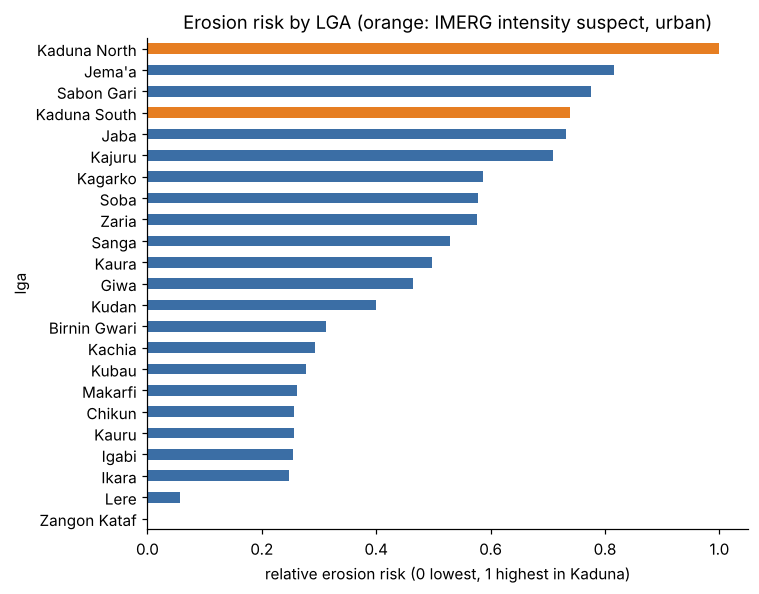

In [6]:
# Rank all 23 LGAs by erosion index; orange bars mark LGAs whose IMERG rain is suspect.
ax = table.sort_values("erosion_index")["erosion_index"].plot.barh(
    figsize=(7, 5.5),
    color=table.sort_values("erosion_index")["imerg_suspect"].map(
        {True: "#e67e22", False: "#3b6ea5"}
    ),
)
ax.set_xlabel("relative erosion risk (0 lowest, 1 highest in Kaduna)")
ax.set_title("Erosion risk by LGA (orange: IMERG intensity suspect, urban)")
plt.tight_layout()

## 3. Infiltration, and save

In [7]:
# Infiltration from hydrologic soil group, then save the A10 table.
table["infiltration"] = table[lrc.group_column].map(
    {"A": "High", "B": "Moderate", "C": "Low", "D": "Very low"}
)
write_csv(table.reset_index(names="lga"), cfg.paths.output_dir / "a10" / "a10_lga_land_risk.csv")
table[lrc.group_column].value_counts()

soil_hydrologic_group
B    23
Name: count, dtype: int64

Every LGA's cropland is hydrologic group B (moderate infiltration), so infiltration does not separate LGAs; on cards it depends on the crops' ground cover and rooting, which the engine scores.